## Explanations via Gradient Similarity

The explanation will be formulated on the basis of the top most influential similar samples from the training set.

In [1]:
!pwd
import sys
sys.path.append('./wingbeats/')
sys.path.append('./influenciae/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import glob
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling
from tensorflow.keras.losses import SparseCategoricalCrossentropy, CategoricalCrossentropy

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-02-01 17:19:46.608279: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-01 17:19:47.154953: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
metafolder = './beexplainable/metafiles/Fungi/raw/toloka_CBR/' # same metafolder for masked and masked_bbox

CLASSES_PATH = metafolder + '/classes.txt'
FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'

IMAGES_PATH_NEIGHBORS = metafolder + 'images_neighbors.txt'
IMAGES_LABELS_PATH_NEIGHBORS = metafolder + 'image_class_labels_neighbors.txt'
IMAGES_PATH_TASKS123 = metafolder + 'images_tasks123.txt'
IMAGES_LABELS_PATH_TASKS123 = metafolder + 'image_class_labels_tasks123.txt'
SOFT_PREDS = './beexplainable/metafiles/Fungi/raw/softmax_preds.npy'

MODELS_PATH  = './beexplainable/models/'

### Load Images

In [5]:
#batch_size = 64
img_height = img_width = 224

**Note**: The neighbors in the 'training set' are all the Andrena samples from images_5_cleaned.txt without the 30 samples selected for the three Toloka tasks.

In [6]:
# Read file IDs and corresponding class labels of the set of neighbors
img_dict_neigh = mr.metafile_to_dict(IMAGES_PATH_NEIGHBORS)
img_label_dict_neigh = mr.metafile_to_dict(IMAGES_LABELS_PATH_NEIGHBORS)
file_ids_neigh = list( img_dict_neigh.keys() )
y_true_neigh   = list( img_label_dict_neigh.values() )
y_true_neigh   = np.asarray(y_true_neigh, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
print(str(len(y_true_neigh)) + ' neighbors')

# Read file IDs and corresponding class labels of the samples for Task 2
img_dict_t123 = mr.metafile_to_dict(IMAGES_PATH_TASKS123)
img_label_dict_t123 = mr.metafile_to_dict(IMAGES_LABELS_PATH_TASKS123)
file_ids_t123 = list( img_dict_t123.keys() )
y_true_t123   = list( img_label_dict_t123.values() )
y_true_t123   = np.asarray(y_true_t123, dtype = np.uint8) - 1
print(str(len(y_true_t123)) + ' samples in Toloka')

610 neighbors
60 samples in Toloka


In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Russula_emetica', 'Russula_paludosa', 'Russula_rosea']

In [8]:
# The influenciae library requires one-hot encoded label vectors
enc = OneHotEncoder(sparse=False)
enc.fit(np.array([0, 1, 2]).reshape(-1, 1))
y_true_t123_oh = enc.transform(y_true_t123.reshape(len(y_true_t123), 1))
y_true_neigh_oh = enc.transform(y_true_neigh.reshape(len(y_true_neigh), 1))

In [9]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_neigh, list(img_dict_neigh.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2024-02-01 17:19:47.243677: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [10]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(file_ids_neigh, y_true_neigh_oh, parse_image_lab)
train_set = train_set.cache().prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))

In [14]:
# Create dataset for the test samples, too
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_t123, list(img_dict_t123.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH), label)

# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids_t123, y_true_t123_oh, parse_image_lab)
test_set = test_set.cache().prefetch(tf.data.experimental.AUTOTUNE)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2024-02-01 17:31:06.106666: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


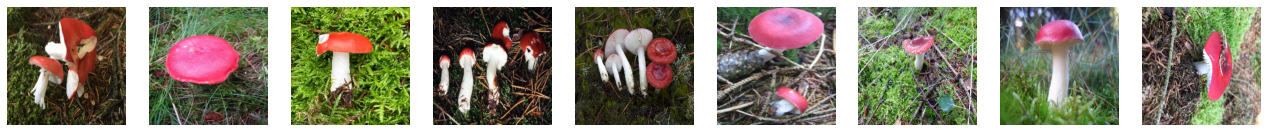

In [29]:
# Plot test samples
plt.figure(figsize = (25, 10))
num_cols = 10
with tf.device('/CPU:0'):
    i = 1
    for img, lab in test_set:
        plt.subplot(1, num_cols, i)
        plt.imshow(img)
        #plt.title(classes[lab.numpy()])
        plt.axis("off")
        i += 1
        if i == 10: break
plt.show()

### Load Model

In [30]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi'
print(model_name)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_raw_Fungi


In [31]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### Compute Explanations

In [32]:
from deel.influenciae.common import InfluenceModel
from deel.influenciae.rps import RepresenterPointL2
from deel.influenciae.utils import ORDER
from deel.influenciae.plots import plot_datacentric_explanations, plot_most_influential_images
from tensorflow.keras.losses import Reduction

In [33]:
lambda_regularization = 0.1
rps_l2 = RepresenterPointL2(model, train_set.batch(20),
                            loss_function=CategoricalCrossentropy(from_logits=True, reduction=Reduction.NONE),
                            lambda_regularization=lambda_regularization, epochs=5)

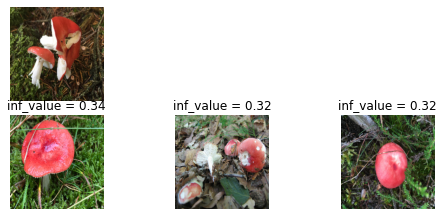

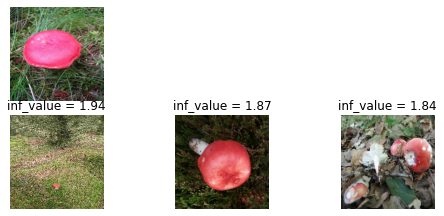

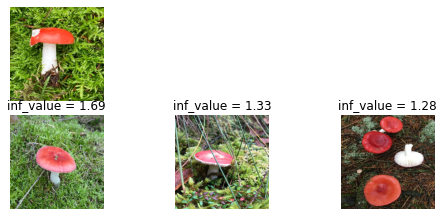

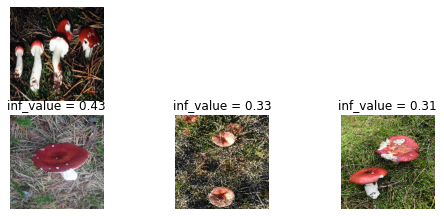

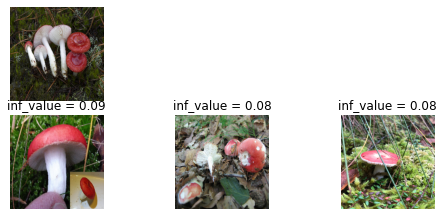

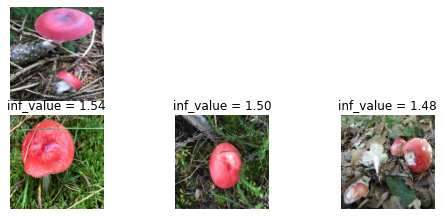

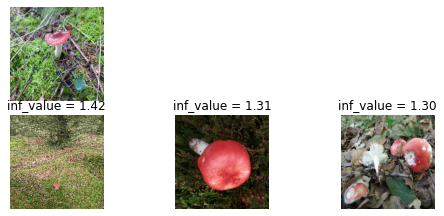

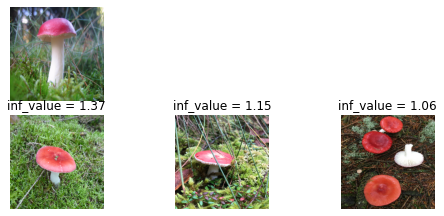

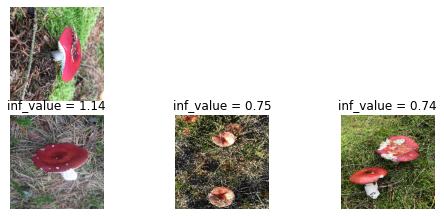

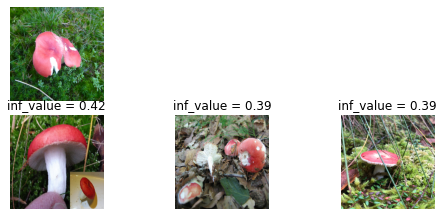

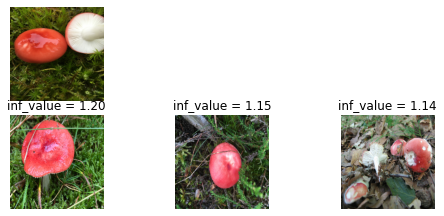

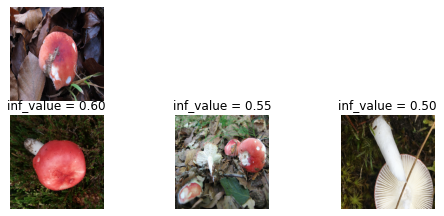

In [34]:
explanations = rps_l2.top_k(test_set.batch(5),
                           train_set.take(600).batch(5), k=3)

i, num_examples = 0, 10
for (img, label), top_k_values, top_k_img in explanations.unbatch().as_numpy_iterator():
    plot_datacentric_explanations(img, (top_k_img, top_k_values))
    if i > num_examples: break
    else: i += 1

In [ ]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
loaded_soft = np.load(SOFT_PREDS)
j = 0
for (img, label), top_k_values, top_k_img in explanations.unbatch().as_numpy_iterator():

    spec_pred_id = np.argmax(loaded_soft[int(file_ids_t123[j])-1], axis=-1)
    spec_pred_prob = int(np.round(np.max(loaded_soft[int(file_ids_t123[j])-1]),2)*100)

    fig = plt.figure(constrained_layout=True, figsize=(11, 11))
    axs = fig.subplot_mosaic([['MainFig', 'MainFig', 'MainFig'],['BottomLeft', 'BottomMid', 'BottomRight']],
                              gridspec_kw={'height_ratios':[5, 3]})

    # Plot original unsegmented images via nearest neighbor
    axs['BottomLeft'].imshow(top_k_img[0])
    axs['BottomMid'].imshow(top_k_img[1])
    axs['BottomRight'].imshow(top_k_img[2])

    axs['MainFig'].imshow(img)
    axs['BottomLeft'].axes.get_xaxis().set_ticks([]); axs['BottomLeft'].axes.get_yaxis().set_ticks([])
    axs['BottomMid'].axes.get_xaxis().set_ticks([]); axs['BottomMid'].axes.get_yaxis().set_ticks([])
    axs['BottomMid'].set_title('Our model is ' + str(spec_pred_prob) + '% confident\nthat this bee is ' + classes[spec_pred_id].replace('_', ' ') + ' because it looks like:',
                         color='red', fontsize=25, weight='bold')
    axs['BottomRight'].axes.get_xaxis().set_ticks([]); axs['BottomRight'].axes.get_yaxis().set_ticks([])
    axs['MainFig'].axes.get_xaxis().set_ticks([]); axs['MainFig'].axes.get_yaxis().set_ticks([])

    img_id = img_dict_t123[file_ids_t123[j]].split('/')[1].split('.')[0]
    for tpath in task13_paths:
        if img_id in tpath:
            fig.savefig('./beexplainable/toloka/fungi/images/task2_examples_reppoint_imgs/' + tpath.split('/')[-1])
            break
    j += 1